# Dataset Type

In [ ]:
DATASET_TYPE = "internal" # Options are "internal" or "downloaded"

# Load Data

In [ ]:
# Import scikit-learn dataset library
from sklearn import datasets

if DATASET_TYPE == "internal":
  rf_data = datasets.load_breast_cancer()

  X = rf_data.data
  y = rf_data.target

  feature_names = rf_data.feature_names
  labels = rf_data.target_names
  cm_labels = labels

# OR: Download Dataset from file

In [ ]:
import numpy as np
import pandas as pd

if DATASET_TYPE == "downloaded":
  rf_data = pd.read_csv('http://nrvis.com/data/mldata/breast-cancer-wisconsin_wdbc.csv')

  X = rf_data.iloc[:, 2:].to_numpy()
  y = rf_data.iloc[:, 1].to_numpy()
  feature_names = rf_data.columns[2:]
  labels = feature_names[1]
  cm_labels = ["malignant", "benign"]

  # Map labels from ['M', 'B'] to [0, 1] space
  y = np.where(y=='M', 0, 1)

# Explore the Data

In [ ]:
# print the names of the features
print("Features: ", feature_names)

# print the label type of targets
print("Labels: ", labels)

Features:  ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
Labels:  ['malignant' 'benign']


# Split the Data into Train and Test Sets

In [ ]:
# Import train_test_split function
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((455, 30), (114, 30), (455,), (114,))

# Generate the Model

In [ ]:
from sklearn.ensemble import RandomForestClassifier  # Import Random Forest Classifier

# Update hyperparameters like n_estimators, criterion, max_depth, min_samples_split etc. using details available at -
# https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

# Create Random Forest classifer object
clf = RandomForestClassifier()

# Train Random Forest Classifer
clf.fit(X_train,y_train)

RandomForestClassifier()

# Predict on Test Data

In [ ]:
#Predict the response for test dataset
y_pred = clf.predict(X_test)

# Evaluate on Test data

In [ ]:
#Import scikit-learn metrics module for accuracy calculation
from sklearn import metrics

# Model Accuracy: how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

# Model Precision: what percentage of positive tuples are labeled as such?
print("Precision:",metrics.precision_score(y_test, y_pred))

# Model Recall: what percentage of positive tuples are labelled as such?
print("Recall:",metrics.recall_score(y_test, y_pred))

Accuracy: 0.9385964912280702
Precision: 0.9315068493150684
Recall: 0.9714285714285714


# Plot Confusion Matrix

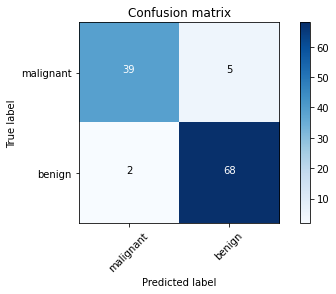

In [ ]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(cm, classes, normalize=False, title='Confusion matrix', cmap=plt.cm.Blues):
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt), horizontalalignment="center", color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

cm = confusion_matrix(y_test, y_pred)

plot_confusion_matrix(cm, cm_labels)  
plt.show()

# Visualize a single Tree from the Random Forest

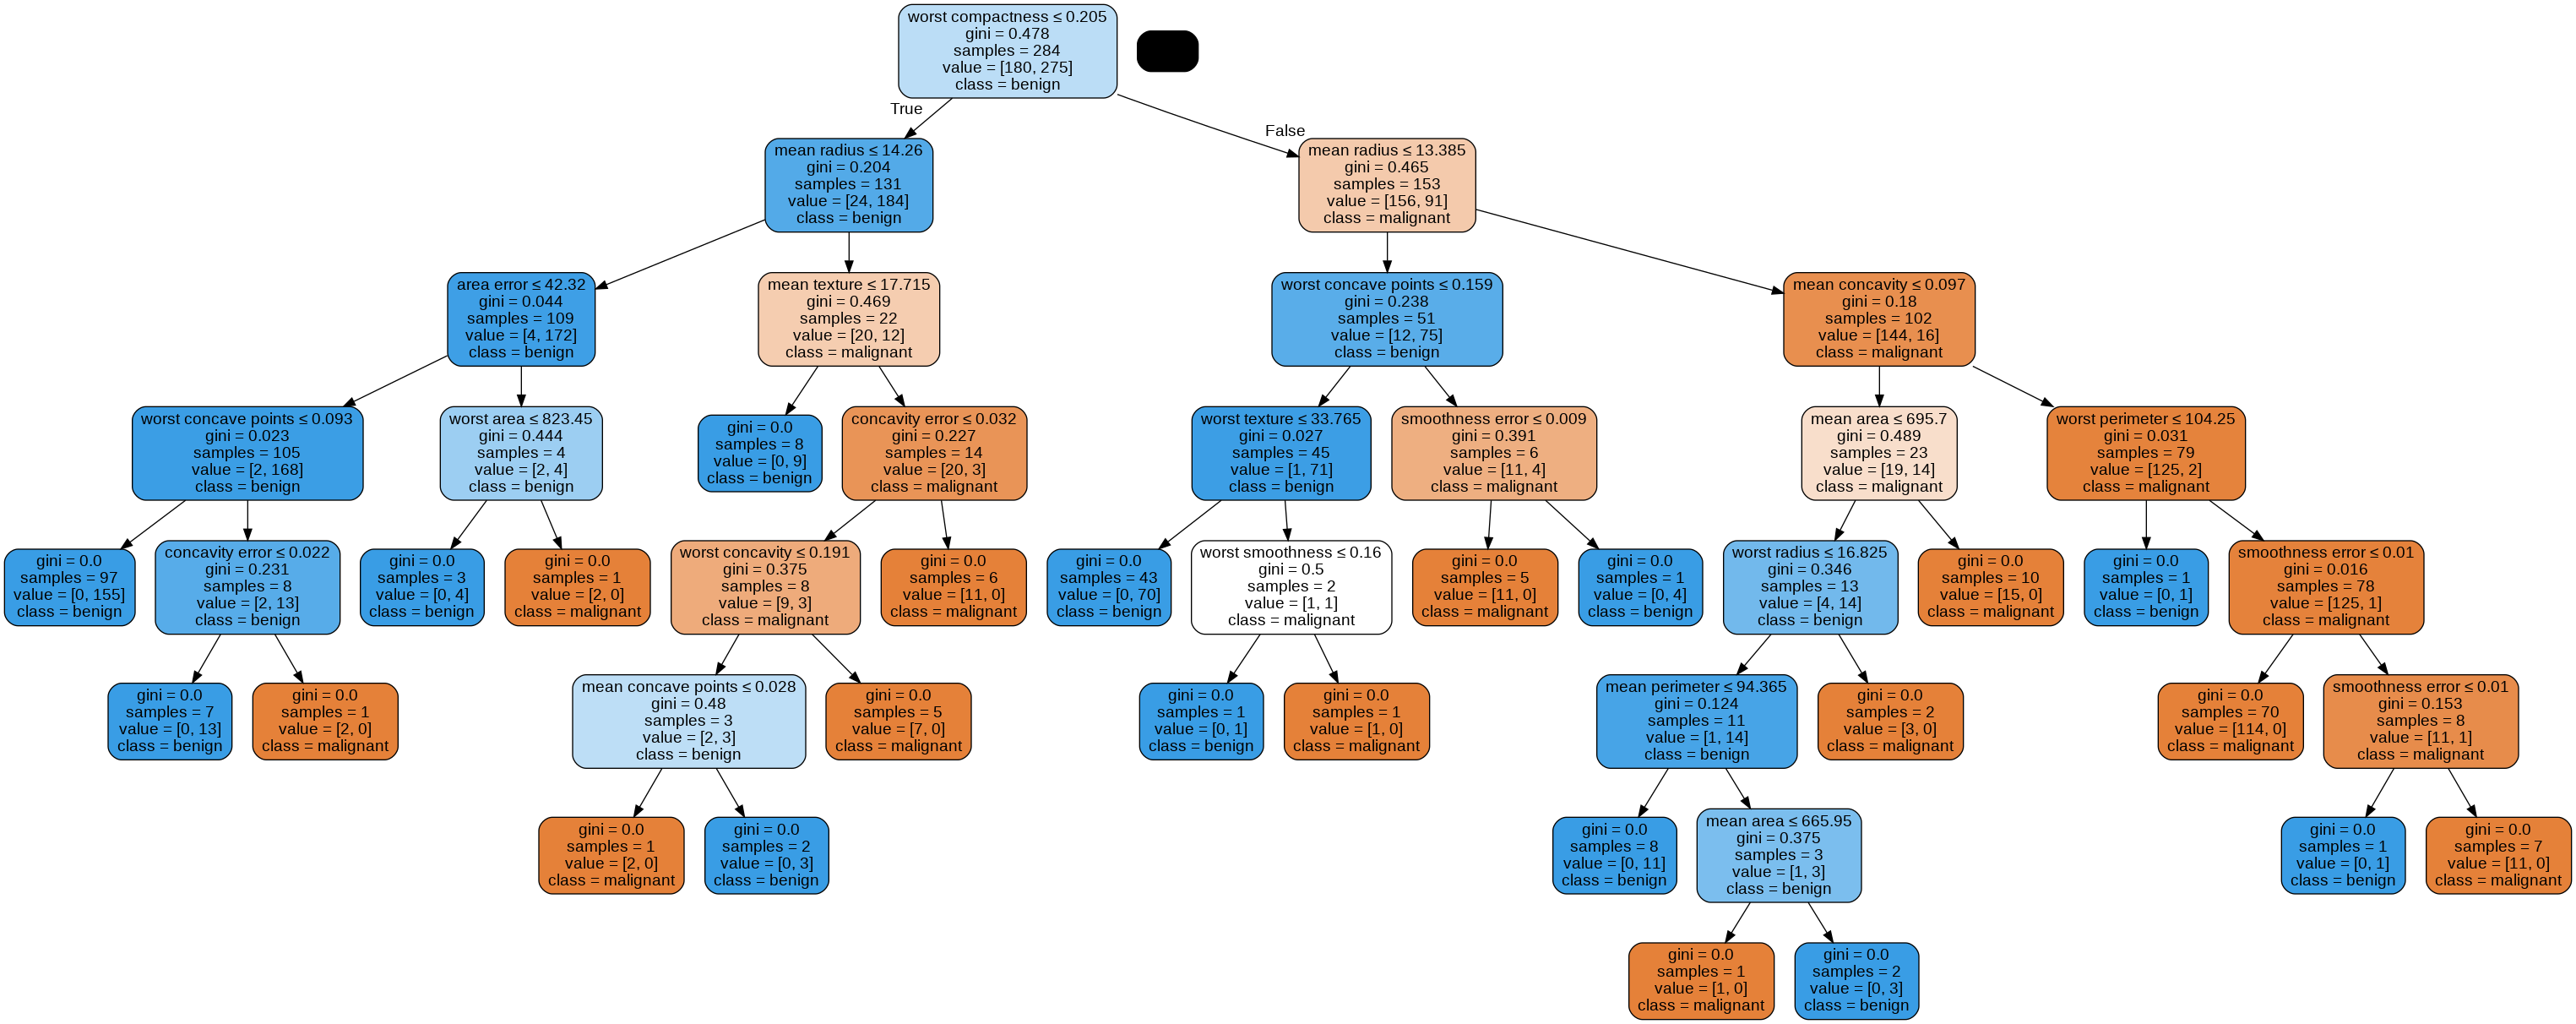

In [ ]:
from sklearn.tree import export_graphviz
#from sklearn.externals.six import StringIO  (if sklearn.externals.six do not work, then, try using only six)
from six import StringIO
from IPython.display import Image  
import pydotplus

TREE_INDEX = 0  # Enter an Index in the range 0 and (clf.n_estimators - 1)

# Extract single tree
estimator = clf.estimators_[TREE_INDEX]

dot_data = StringIO()
export_graphviz(estimator, out_file=dot_data,  
                filled=True, rounded=True,
                special_characters=True,feature_names=feature_names,class_names=labels)
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())  
graph.write_png('decision_tress.png')
Image(graph.create_png())